In [1]:
# download module needed for reading ply into np
!pip -q install plyfile

In [10]:
# put the directory where the .ply file is stored
from google.colab import drive
drive.mount("/content/drive")
RESULT_DIR = "/content/drive/MyDrive/" # CHANGE THIS TO DIR CONTATINNG .PLY FILE
!ls "$RESULT_DIR"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
point_cloud_6999.ply


In [11]:
from pathlib import Path
from plyfile import PlyData
import numpy as np

# Locate trained Gaussian Splatting .ply file
ply_files = sorted(Path(RESULT_DIR).rglob("*.ply"))

print("Found PLY files:")
for p in ply_files:
    print(p)

assert ply_files, "No PLY files found. Check RESULT_DIR."

PLY_PATH = ply_files[-1]
ply = PlyData.read(str(PLY_PATH))
vertices = ply["vertex"].data

print("Number of Gaussians:", len(vertices))
print("Properties:", vertices.dtype.names)

Found PLY files:
/content/drive/MyDrive/ACM AI/Minecraft 3D Reconstruction Project - Fall 26/splats/shoe_7000/ply/point_cloud_6999.ply
Number of Gaussians: 1927984
Properties: ('x', 'y', 'z', 'f_dc_0', 'f_dc_1', 'f_dc_2', 'f_rest_0', 'f_rest_1', 'f_rest_2', 'f_rest_3', 'f_rest_4', 'f_rest_5', 'f_rest_6', 'f_rest_7', 'f_rest_8', 'f_rest_9', 'f_rest_10', 'f_rest_11', 'f_rest_12', 'f_rest_13', 'f_rest_14', 'f_rest_15', 'f_rest_16', 'f_rest_17', 'f_rest_18', 'f_rest_19', 'f_rest_20', 'f_rest_21', 'f_rest_22', 'f_rest_23', 'f_rest_24', 'f_rest_25', 'f_rest_26', 'f_rest_27', 'f_rest_28', 'f_rest_29', 'f_rest_30', 'f_rest_31', 'f_rest_32', 'f_rest_33', 'f_rest_34', 'f_rest_35', 'f_rest_36', 'f_rest_37', 'f_rest_38', 'f_rest_39', 'f_rest_40', 'f_rest_41', 'f_rest_42', 'f_rest_43', 'f_rest_44', 'opacity', 'scale_0', 'scale_1', 'scale_2', 'rot_0', 'rot_1', 'rot_2', 'rot_3')


In [16]:
# Extract Gaussian centers
MIN_OPACITY = 0.1

points = np.column_stack([
    vertices["x"],
    vertices["y"],
    vertices["z"]
]).astype(np.float32)


# Convert .ply representation to approximate RGB
SH_C0 = 0.28209479177387814

colors = np.column_stack([
    vertices["f_dc_0"],
    vertices["f_dc_1"],
    vertices["f_dc_2"]
])

colors = np.clip(0.5 + SH_C0 * colors, 0, 1)


# Convert stored opacity logits to opacity values
logits = vertices["opacity"].astype(np.float64)
opacities = 1 / (1 + np.exp(-np.clip(logits, -80, 80)))

# Exclude low-opacity splats
mask = (
    (opacities > MIN_OPACITY)
    & np.isfinite(points).all(axis=1)
    & np.isfinite(colors).all(axis=1)
)

points = points[mask]
colors = colors[mask]

print(f"Gaussians retained: {len(points)}/{len(vertices)}")

Gaussians retained: 920322/1927984


In [17]:
RESOLUTION = 2048

# Determine point-cloud bounding box
min_bound = points.min(axis=0)
max_bound = points.max(axis=0)

extent = max_bound - min_bound
voxel_size = extent.max() / RESOLUTION

# Assign each Gaussian center to a voxel
voxel_indices = np.floor(
    (points - min_bound) / voxel_size
).astype(np.int32)

# Merge points occupying the same voxel
unique_voxels, inverse, counts = np.unique(
    voxel_indices,
    axis=0,
    return_inverse=True,
    return_counts=True
)

# Average the colors of points within each voxel
voxel_colors = np.zeros((len(unique_voxels), 3))

for channel in range(3):
    voxel_colors[:, channel] = (
        np.bincount(
            inverse,
            weights=colors[:, channel],
            minlength=len(unique_voxels)
        ) / counts
    )

# Calculate the real-world center of each voxel
voxel_centers = (
    min_bound
    + (unique_voxels + 0.5) * voxel_size
)

print("Input Gaussians:", len(points))
print("Occupied voxels:", len(unique_voxels))
print("Voxel size:", voxel_size)

Input Gaussians: 920322
Occupied voxels: 275160
Voxel size: 0.00485029


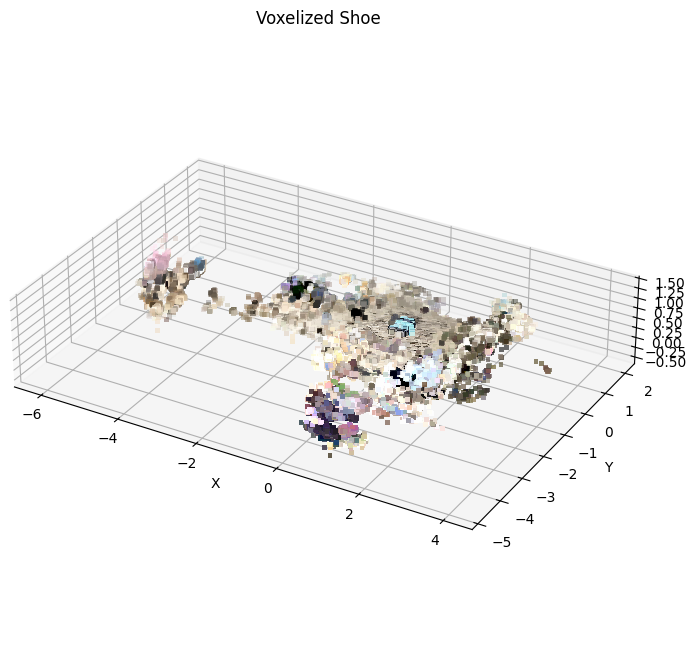

In [18]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    voxel_centers[:, 0],
    voxel_centers[:, 1],
    voxel_centers[:, 2],
    c=voxel_colors,
    s=12,
    marker="s",
    linewidths=0
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Voxelized Shoe")

ax.set_box_aspect(np.maximum(extent, 1e-6))
plt.show()